In [1]:
# =============================================================================
# ETAP 1: IMPORTY I KONFIGURACJA ŚCIEŻEK
# =============================================================================
import os
import re
import json
import csv
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

# Definicja katalogu wejściowego z plikami HTML oraz katalogu wyjściowego na wyniki
INPUT_DIR = Path(r"C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\oscars\output")
OUTPUT_DIR = Path(r"C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\Wyniki")

# Automatyczne utworzenie katalogu docelowego w przypadku jego braku
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INDEX_PATH = INPUT_DIR / "index.html"
JSON_OUTPUT_PATH = OUTPUT_DIR / "oscars_structured.json"
CSV_OUTPUT_PATH = OUTPUT_DIR / "oscars_clean.csv"

print("=" * 80)
print("[ETAP 1: TECHNIKALIA] Ścieżki zostały skonfigurowane.")
print(f" -> Katalog wejściowy (pliki HTML): {INPUT_DIR}")
print(f" -> Katalog wyjściowy (pliki wyników): {OUTPUT_DIR}")
print("=" * 80 + "\n")

[ETAP 1: TECHNIKALIA] Ścieżki zostały skonfigurowane.
 -> Katalog wejściowy (pliki HTML): C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\oscars\output
 -> Katalog wyjściowy (pliki wyników): C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\Wyniki



In [2]:
# =============================================================================
# ETAP 2: SCRAPING I POBIERANIE DANYCH (INDEX ORAZ PODSTRONY)
# =============================================================================

def pobierz_indeks_ceremonii(plik_indeksu: Path) -> pd.DataFrame:
    """Odczytuje plik index.html i tworzy listę edycji wraz ze ścieżkami relatywnymi."""
    if not plik_indeksu.exists():
        print(f"Brak pliku indeksu: {plik_indeksu}")
        return pd.DataFrame()

    try:
        with open(plik_indeksu, encoding="utf-8") as f:
            soup = BeautifulSoup(f, "html.parser")

        lista_ceremonii = []
        for card in soup.select(".year-card"):
            link = card.find("a")
            rok = card.get("data-year")
            if link and "href" in link.attrs and rok:
                lista_ceremonii.append({
                    "year": int(rok),
                    "page_id": Path(link["href"]).stem,
                    "relative_path": link["href"]
                })

        return pd.DataFrame(lista_ceremonii).sort_values("year").reset_index(drop=True)
    except Exception as e:
        print(f"Błąd podczas wczytywania index.html: {e}")
        return pd.DataFrame()


def pobierz_dane_z_podstrony(katalog_glowny: Path, relatywna_sciezka: str) -> list:
    """Parsuje pojedynczą podstronę HTML i wyciąga rekordy nominacji oraz wygranych."""
    sciezka = katalog_glowny / relatywna_sciezka
    if not sciezka.exists():
        return []

    rekordy = []
    try:
        with open(sciezka, encoding="utf-8") as f:
            soup = BeautifulSoup(f, "html.parser")

        h1 = soup.find("h1")
        rok = None
        if h1:
            match = re.search(r'\b(19\d\d|20\d\d)\b', h1.get_text())
            if match:
                rok = int(match.group(1))

        meta = soup.select_one(".meta-info")
        page_id = meta.get_text(strip=True).replace("Page ID:", "").strip() if meta else sciezka.stem

        for sekcja in soup.select(".category-section"):
            naglowek = sekcja.find("h2")
            if not naglowek:
                continue
            nazwa_kat = re.sub(r'\s+', ' ', naglowek.get_text()).strip()

            for wygrana in sekcja.select(".winner p"):
                tekst = re.sub(r'\s+', ' ', wygrana.get_text()).strip()
                if tekst:
                    rekordy.append({
                        "year": rok,
                        "page_id": page_id,
                        "category": nazwa_kat,
                        "result_type": "winner",
                        "raw_text": tekst
                    })

            for nominacja in sekcja.select(".nominee p"):
                tekst = re.sub(r'\s+', ' ', nominacja.get_text()).strip()
                if tekst:
                    rekordy.append({
                        "year": rok,
                        "page_id": page_id,
                        "category": nazwa_kat,
                        "result_type": "nominee",
                        "raw_text": tekst
                    })
    except Exception as e:
        print(f"Błąd podczas przetwarzania pliku {sciezka}: {e}")

    return rekordy


print("[ETAP 2: SCRAPING DANYCH]")
df_indeks = pobierz_indeks_ceremonii(INDEX_PATH)
print(f" -> Liczba odnalezionych edycji: {len(df_indeks)}")
print(" -> Podgląd pierwszych 3 wierszy ze spisu ceremonii:")
print(df_indeks.head(3).to_string(index=False))

surowe_rekordy = []
for _, wiersz in df_indeks.iterrows():
    surowe_rekordy.extend(pobierz_dane_z_podstrony(INPUT_DIR, wiersz["relative_path"]))

print(f"\n -> Pobrano łącznie {len(surowe_rekordy)} surowych wpisów z podstron.")
print(" -> Podgląd pierwszych 3 nieprzetworzonych wpisów:")
for r in surowe_rekordy[:3]:
    print(f"    * Rok {r['year']} | Kategoria: {r['category']:<25} | Wynik: {r['result_type']:<7} | Raw: {r['raw_text']}")
print("=" * 80 + "\n")

[ETAP 2: SCRAPING DANYCH]
 -> Liczba odnalezionych edycji: 96
 -> Podgląd pierwszych 3 wierszy ze spisu ceremonii:
 year                              page_id                                   relative_path
 1928 c2a21ba5-24b8-4bfa-8b21-94acee068902 pages/c2a21ba5-24b8-4bfa-8b21-94acee068902.html
 1929 40b0571b-da27-4c29-b083-e51cb0d6ed77 pages/40b0571b-da27-4c29-b083-e51cb0d6ed77.html
 1930 c6c710f5-cdb9-4eee-a13f-1b948c26f84d pages/c6c710f5-cdb9-4eee-a13f-1b948c26f84d.html

 -> Pobrano łącznie 10889 surowych wpisów z podstron.
 -> Podgląd pierwszych 3 nieprzetworzonych wpisów:
    * Rok 1928 | Kategoria: ACTOR                     | Wynik: winner  | Raw: Emil Jannings - "The Last Command"
    * Rok 1928 | Kategoria: ACTOR                     | Wynik: nominee | Raw: Richard Barthelmess - "The Noose"
    * Rok 1928 | Kategoria: ACTRESS                   | Wynik: winner  | Raw: Janet Gaynor - "7th Heaven"



In [3]:
# =============================================================================
# ETAP 3: CZYSZCZENIE I SEPARACJA DANYCH
# =============================================================================

def rozdziel_osobe_i_film(surowy_tekst: str):
    """Rozdziela ciąg tekstowy na osobę/podmiot oraz tytuł filmu ujęty w cudzysłów."""
    tekst = str(surowy_tekst).strip()
    if not tekst:
        return None, None

    match_film = re.search(r'"([^"]+)"', tekst)
    film = match_film.group(1).strip() if match_film else None

    if ' - "' in tekst:
        osoba = tekst.split(' - "')[0].strip()
    elif ' - ' in tekst:
        osoba = tekst.split(' - ')[0].strip()
    else:
        osoba = tekst if not film else tekst.replace(f'"{film}"', '').strip()

    osoba = re.sub(r'[\s;,-]+$', '', osoba) if osoba else None
    return (osoba if osoba else None, film if film else None)


def kategoryzuj_grupe(nazwa_kat: str) -> str:
    """Grupuje poszczególne kategorie w uniwersalne grupy tematyczne."""
    kat = str(nazwa_kat).upper()
    if "ACTOR" in kat or "ACTRESS" in kat:
        return "ACTING"
    elif "DIRECTING" in kat:
        return "DIRECTING"
    elif any(k in kat for k in ["BEST PICTURE", "OUTSTANDING PICTURE", "PRODUCTIONS"]):
        return "PICTURE_STUDIO"
    elif any(k in kat for k in ["HONORARY", "SPECIAL", "HUMANITARIAN"]):
        return "SPECIAL_AWARD"
    else:
        return "OTHER_TECHNICAL"


print("[ETAP 3: CZYSZCZENIE I PRZETWARZANIE DANYCH]")
df_dane = pd.DataFrame(surowe_rekordy)

# Usunięcie znaków nowej linii i tabulacji z pól tekstowych
df_dane["raw_text"] = df_dane["raw_text"].astype(str).apply(lambda x: re.sub(r'[\r\n\t]+', ' ', x).strip())
df_dane["category"] = df_dane["category"].astype(str).apply(lambda x: re.sub(r'[\r\n\t]+', ' ', x).strip())

ekstrakcja = df_dane["raw_text"].apply(rozdziel_osobe_i_film)
df_dane["entity"] = [item[0] for item in ekstrakcja]
df_dane["film"] = [item[1] for item in ekstrakcja]
df_dane["category_group"] = df_dane["category"].apply(kategoryzuj_grupe)
df_dane["entry_type"] = df_dane["film"].apply(lambda x: "FILM" if pd.notna(x) and str(x).strip() != "" else "NON_FILM")

df_dane["entity"] = df_dane["entity"].replace("", np.nan)
df_dane["film"] = df_dane["film"].replace("", np.nan)

print(" -> Podgląd 4 wyczyszczonych rekordów:")
print(df_dane[["year", "category_group", "entity", "film", "result_type"]].head(4).to_string(index=False))
print("=" * 80 + "\n")

[ETAP 3: CZYSZCZENIE I PRZETWARZANIE DANYCH]
 -> Podgląd 4 wyczyszczonych rekordów:
 year category_group              entity             film result_type
 1928         ACTING       Emil Jannings The Last Command      winner
 1928         ACTING Richard Barthelmess        The Noose     nominee
 1928         ACTING        Janet Gaynor       7th Heaven      winner
 1928         ACTING      Louise Dresser  A Ship Comes In     nominee



In [4]:
# =============================================================================
# ETAP 4: WYNIKI I STATYSTYKI ZBIORU
# =============================================================================

print("[ETAP 4: ANALIZA WYNIKÓW I STATYSTYKI]")
print(f" -> Zakres lat:               {df_dane['year'].min()} – {df_dane['year'].max()} ({df_dane['year'].nunique()} edycji)")
print(f" -> Łącznie rekordów:         {len(df_dane)}")
print(f" -> Liczba wygranych:         {len(df_dane[df_dane['result_type'] == 'winner'])}")
print(f" -> Liczba nominacji:         {len(df_dane[df_dane['result_type'] == 'nominee'])}")
print(f" -> Unikalne tytuły filmów:   {df_dane['film'].nunique(dropna=True)}")
print(f" -> Unikalne osoby / podmioty: {df_dane['entity'].nunique(dropna=True)}")
print(" -> Kompletność wyciągniętych danych:")
print(f"    - Rozpoznane filmy: {df_dane['film'].notna().mean() * 100:.1f}%")
print(f"    - Rozpoznane osoby: {df_dane['entity'].notna().mean() * 100:.1f}%")
print("=" * 80 + "\n")

[ETAP 4: ANALIZA WYNIKÓW I STATYSTYKI]
 -> Zakres lat:               1928 – 2024 (96 edycji)
 -> Łącznie rekordów:         10889
 -> Liczba wygranych:         2465
 -> Liczba nominacji:         8424
 -> Unikalne tytuły filmów:   5047
 -> Unikalne osoby / podmioty: 7001
 -> Kompletność wyciągniętych danych:
    - Rozpoznane filmy: 97.1%
    - Rozpoznane osoby: 100.0%



In [5]:
# =============================================================================
# ETAP 5: DETEKCJA ANOMALII W DANYCH
# =============================================================================

print("[ETAP 5: DETEKCJA ANOMALII W DANYCH]")

# 1. Odchylenia w liczbie kategorii na dany rok
kat_per_rok = df_dane.groupby('year')['category'].nunique()
srednia_kat = kat_per_rok.mean()
odchylenie_kat = kat_per_rok.std()
anomalie_kat = kat_per_rok[(kat_per_rok < srednia_kat - 1.5 * odchylenie_kat) | (kat_per_rok > srednia_kat + 1.5 * odchylenie_kat)]

# 2. Remisy (kilku zwycięzców w jednej kategorii w tym samym roku)
wygrani_per_kat = df_dane[df_dane['result_type'] == 'winner'].groupby(['year', 'category']).size()
remisy = wygrani_per_kat[wygrani_per_kat > 1]

# 3. Wyniki bez przypisanego filmu (nagrody specjalne lub techniczne)
wyniki_bez_filmu = df_dane[df_dane['film'].isna()]

# 4. Powtarzające się wpisy
duplikaty = df_dane[df_dane.duplicated(subset=['year', 'category', 'raw_text'], keep=False)]

print(f"1. Anomalie w liczbie kategorii na rok (średnia: {srednia_kat:.1f}): wykryto {len(anomalie_kat)} edycji.")
if not anomalie_kat.empty:
    print("   [PRZYKŁADY - Nietypowa liczba kategorii w danych latach]:")
    for r, count in anomalie_kat.head(3).items():
        print(f"    * Rok {r}: {count} kategorii")

print(f"\n2. Anomalie w liczbie wygranych (remisy w 1 kategorii): wykryto {len(remisy)} przypadków.")
if not remisy.empty:
    print("   [PRZYKŁADY - Remisy / kilkukrotne wygrane]:")
    for (r, k), count in remisy.head(3).items():
        print(f"    * Rok {r} | Kategoria: {k} | Wygranych: {count}")

print(f"\n3. Wyniki bez filmu: wykryto {len(wyniki_bez_filmu)} wpisów.")
if not wyniki_bez_filmu.empty:
    print("   [PRZYKŁADY - Brakujące tytuły filmowe]:")
    print(wyniki_bez_filmu[['year', 'category', 'entity', 'raw_text']].head(3).to_string(index=False))

print(f"\n4. Duplikaty rekordów: wykryto {len(duplikaty)} powtórzeń.")
if not duplikaty.empty:
    print("   [PRZYKŁADY - Duplikaty w bazie]:")
    print(duplikaty[['year', 'category', 'raw_text']].head(3).to_string(index=False))

print("=" * 80 + "\n")

[ETAP 5: DETEKCJA ANOMALII W DANYCH]
1. Anomalie w liczbie kategorii na rok (średnia: 24.4): wykryto 8 edycji.
   [PRZYKŁADY - Nietypowa liczba kategorii w danych latach]:
    * Rok 1928: 13 kategorii
    * Rok 1929: 7 kategorii
    * Rok 1930: 8 kategorii

2. Anomalie w liczbie wygranych (remisy w 1 kategorii): wykryto 63 przypadków.
   [PRZYKŁADY - Remisy / kilkukrotne wygrane]:
    * Rok 1928 | Kategoria: CINEMATOGRAPHY | Wygranych: 2
    * Rok 1928 | Kategoria: SPECIAL AWARD | Wygranych: 2
    * Rok 1932 | Kategoria: ACTOR | Wygranych: 2

3. Wyniki bez filmu: wykryto 315 wpisów.
   [PRZYKŁADY - Brakujące tytuły filmowe]:
 year                category           entity         raw_text
 1928     ENGINEERING EFFECTS   Ralph Hammeras   Ralph Hammeras
 1928     ENGINEERING EFFECTS Nugent Slaughter Nugent Slaughter
 1928 WRITING (Title Writing)   Joseph Farnham   Joseph Farnham

4. Duplikaty rekordów: wykryto 19 powtórzeń.
   [PRZYKŁADY - Duplikaty w bazie]:
 year              category  

[ETAP 6: WIZUALIZACJA DANYCH]


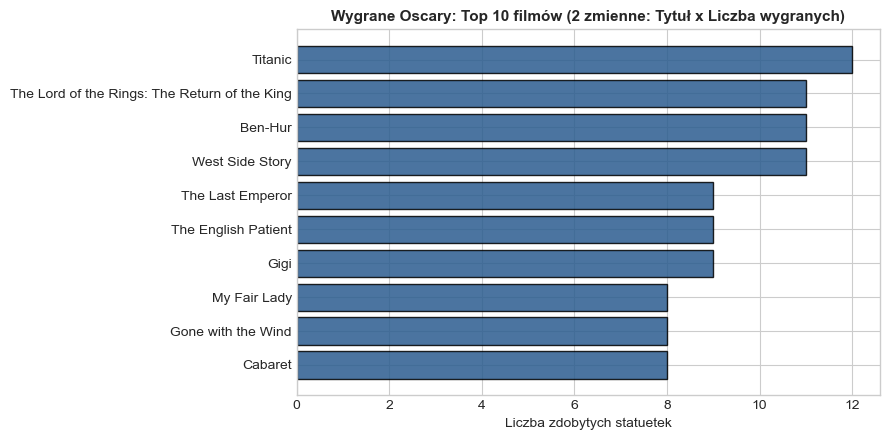

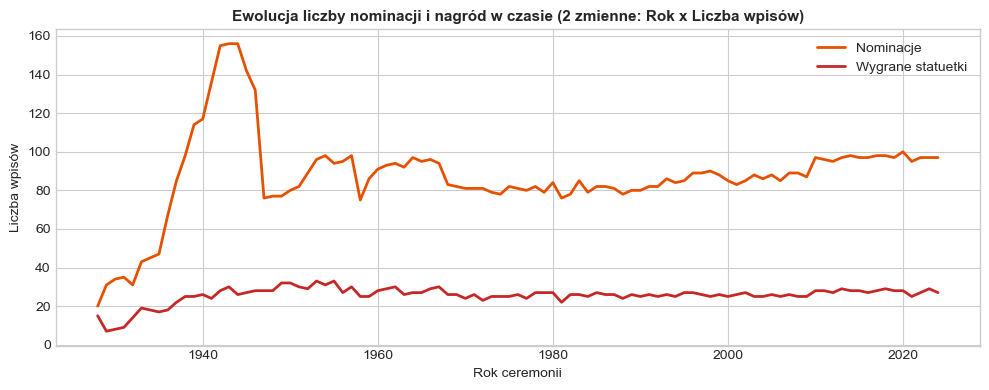

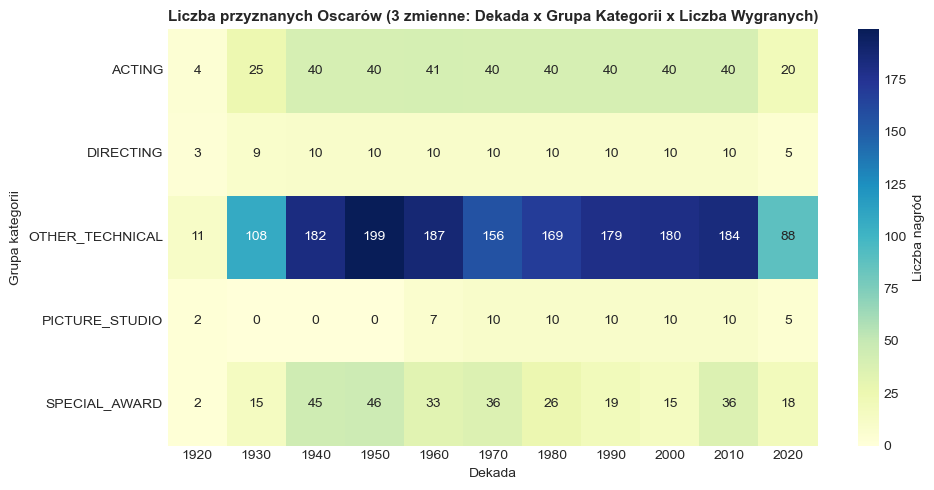

In [6]:
# =============================================================================
# ETAP 6: GENEROWANIE I WIZUALIZACJA WYKRESÓW
# =============================================================================

print("[ETAP 6: WIZUALIZACJA DANYCH]")
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Wykres 1 (2 zmienne): Top 10 filmów z największą liczbą wygranych
plt.figure(figsize=(9, 4.5))
top_filmy = df_dane[df_dane['result_type'] == 'winner']['film'].value_counts().head(10).sort_values(ascending=True)
plt.barh(top_filmy.index, top_filmy.values, color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.title("Wygrane Oscary: Top 10 filmów (2 zmienne: Tytuł x Liczba wygranych)", fontsize=11, fontweight='bold')
plt.xlabel("Liczba zdobytych statuetek")
plt.tight_layout()
plt.show()

# Wykres 2 (2 zmienne): Liczba nominacji i wygranych w latach 1928-2024
plt.figure(figsize=(10, 4))
trendy = df_dane.groupby(['year', 'result_type']).size().unstack(fill_value=0)
plt.plot(trendy.index, trendy['nominee'], label='Nominacje', color='#e65100', linewidth=2)
plt.plot(trendy.index, trendy['winner'], label='Wygrane statuetki', color='#c62828', linewidth=2)
plt.title("Ewolucja liczby nominacji i nagród w czasie (2 zmienne: Rok x Liczba wpisów)", fontsize=11, fontweight='bold')
plt.xlabel("Rok ceremonii")
plt.ylabel("Liczba wpisów")
plt.legend()
plt.tight_layout()
plt.show()

# Wykres 3 (3 zmienne): Heatmapa wygranych według dekad i grup kategorii
plt.figure(figsize=(10, 5))
df_dane['decade'] = (df_dane['year'] // 10) * 10
dane_3zm_dekady = df_dane[df_dane['result_type'] == 'winner'].groupby(['decade', 'category_group']).size().unstack(fill_value=0)

sns.heatmap(
    dane_3zm_dekady.T, 
    cmap='YlGnBu', 
    annot=True, 
    fmt="d", 
    cbar_kws={'label': 'Liczba nagród'}
)
plt.title("Liczba przyznanych Oscarów (3 zmienne: Dekada x Grupa Kategorii x Liczba Wygranych)", fontsize=11, fontweight='bold')
plt.xlabel("Dekada")
plt.ylabel("Grupa kategorii")
plt.tight_layout()
plt.show()

print("=" * 80 + "\n")

In [8]:
# =============================================================================
# ETAP 7: TWORZENIE I ZAPIS PLIKÓW CSV ORAZ JSON
# =============================================================================

import json
import csv
import re
import numpy as np
import pandas as pd

print("[ETAP 7: GENEROWANIE PLIKÓW CSV I JSON]")

# --- FUNKCJE POMOCNICZE DO CZYSZCZENIA I KOREKTY DANYCH ---

def _clean_field(value):
    """Usuwa zbędne nawiasy otaczające oraz interpunkcję końcową (średniki, kropki)."""
    if pd.isna(value) or not isinstance(value, str):
        return value
    val = value.strip()
    if val.startswith("(") and val.endswith(")"):
        val = val[1:-1].strip()
    val = re.sub(r'[;.,\s]+$', '', val)
    return val if val else None

def _parse_entity_and_film(raw_text):
    """Parsuje pole raw_text w przypadku błędnie wyekstrahowanych pseudonimów lub braku filmu."""
    if pd.isna(raw_text) or not isinstance(raw_text, str):
        return None, None
    raw = raw_text.strip()
    
    if "for the creation of" in raw:
        parts = raw.split("for the creation of")
        return _clean_field(parts[0]), _clean_field(parts[1]) if len(parts) > 1 else None
    
    match = re.match(r'^(.*?)\s*[-–—]\s*(.*)$', raw)
    if match:
        entity, film = match.groups()
        return _clean_field(entity), _clean_field(film)
    
    return _clean_field(raw), None

def _process_row_fields(row):
    """Aplikuje reguły czyszczące dla pojedynczego wiersza DataFrame."""
    entity = _clean_field(row.get("entity"))
    film = _clean_field(row.get("film"))
    raw_text = str(row.get("raw_text", ""))

    # Korekta w przypadku, gdy jako film wyekstrahowano sam pseudonim w cudzysłowie (np. "Chick") lub brak filmu
    if (film and film.startswith('"') and film.endswith('"')) or not film:
        parsed_entity, parsed_film = _parse_entity_and_film(raw_text)
        if parsed_entity:
            entity = parsed_entity
        if parsed_film:
            film = parsed_film

    return pd.Series([entity, film], index=["entity", "film"])

# Wykonanie automatycznej korekty i czyszczenia pól bezpośrednio w df_dane przed generowaniem wyjścia
df_dane[["entity", "film"]] = df_dane.apply(_process_row_fields, axis=1)


# --- ZAPIS DO HIERARCHICZNEGO PLIKU JSON ---

struktura_json = {}
for rok, grupa_roczna in df_dane.groupby("year"):
    key_rok = str(int(rok))
    page_id = str(grupa_roczna["page_id"].iloc[0])
    kategorie = {}

    for kategoria, grupa_kat in grupa_roczna.groupby("category"):
        wygrani = []
        nominowani = []

        for _, wiersz in grupa_kat.iterrows():
            item = {
                "entity": wiersz["entity"] if pd.notna(wiersz["entity"]) else None,
                "film": wiersz["film"] if pd.notna(wiersz["film"]) else None,
                "entry_type": wiersz["entry_type"],
                "raw_text": wiersz["raw_text"]
            }
            if wiersz["result_type"] == "winner":
                wygrani.append(item)
            else:
                nominowani.append(item)

        kategorie[str(kategoria)] = {
            "winners": wygrani,
            "nominees": nominowani
        }

    struktura_json[key_rok] = {
        "page_id": page_id,
        "total_records": len(grupa_roczna),
        "categories": kategorie
    }

with open(JSON_OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(struktura_json, f, ensure_ascii=False, indent=2)

print(f" -> Zapisano plik JSON pod ścieżką: {JSON_OUTPUT_PATH.resolve()}")


# --- ZAPIS DO SPŁASZCZONEGO PLIKU CSV ---

kolumny_csv = ["year", "page_id", "category", "category_group", "result_type", "entry_type", "entity", "film", "raw_text"]
df_export = df_dane[kolumny_csv].copy()

for col in df_export.select_dtypes(include=["object"]).columns:
    df_export[col] = df_export[col].fillna("").astype(str).apply(lambda val: re.sub(r'[\r\n\t]+', ' ', val).strip())

df_export.replace("", np.nan).to_csv(
    CSV_OUTPUT_PATH,
    index=False,
    sep=";",
    encoding="utf-8-sig",
    quoting=csv.QUOTE_MINIMAL
)

print(f" -> Zapisano plik CSV pod ścieżką:  {CSV_OUTPUT_PATH.resolve()}")
print("\nPodgląd wygenerowanej tabeli CSV (pierwsze 3 wiersze):")
print(df_export.head(3).to_string(index=False))

print("\n" + "=" * 80)
print("Przetwarzanie danych zakończone sukcesem. Wszystkie pliki wyjściowe zostały poprawnie wygenerowane.")
print("=" * 80)

[ETAP 7: GENEROWANIE PLIKÓW CSV I JSON]
 -> Zapisano plik JSON pod ścieżką: C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\Wyniki\oscars_structured.json
 -> Zapisano plik CSV pod ścieżką:  C:\Users\dawid\Desktop\Python Data Science Engineer\Projekt semestralny 1a\Wyniki\oscars_clean.csv

Podgląd wygenerowanej tabeli CSV (pierwsze 3 wiersze):
 year                              page_id category category_group result_type entry_type              entity             film                           raw_text
 1928 c2a21ba5-24b8-4bfa-8b21-94acee068902    ACTOR         ACTING      winner       FILM       Emil Jannings The Last Command Emil Jannings - "The Last Command"
 1928 c2a21ba5-24b8-4bfa-8b21-94acee068902    ACTOR         ACTING     nominee       FILM Richard Barthelmess        The Noose  Richard Barthelmess - "The Noose"
 1928 c2a21ba5-24b8-4bfa-8b21-94acee068902  ACTRESS         ACTING      winner       FILM        Janet Gaynor       7th Heaven        Janet Ga